# # 13 · Diffusion language models (LLaDA / MDLM / Dream)
#
# Autoregressive LMs write left-to-right. **Masked discrete diffusion** LMs instead start from a fully masked sequence and
# *denoise* it in parallel over several steps:
#
# * **Forward (noising):** mask each token independently with probability `t ~ U(0,1)`.
# * **Model:** a *bidirectional* Transformer that predicts the original tokens at the masked positions.
# * **Loss:** cross-entropy on masked positions, weighted by `1/t`.
# * **Sampling:** start all-`[MASK]`; at each step predict everything, keep the most confident predictions, re-mask the rest.

---

### At a glance

| | |
|---|---|
| **Family** | Diffusion language models |
| **Representative models** | LLaDA, MDLM, Dream, Mercury |
| **Core idea** | Learn to denoise randomly masked text; generate by iteratively unmasking all positions in parallel. |
| **Compute / memory** | O(T²) per step × number of denoising steps |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 148 s on a laptop CPU |

### What you will learn

- Implement the masked-diffusion objective with 1/t weighting
- Sample with confidence-based iterative unmasking
- Do infilling with bidirectional context

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np
from llmarch import *
setup_style()
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 1500; T = 64
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]; MASK = V

# ## Forward process: progressively masking a sentence

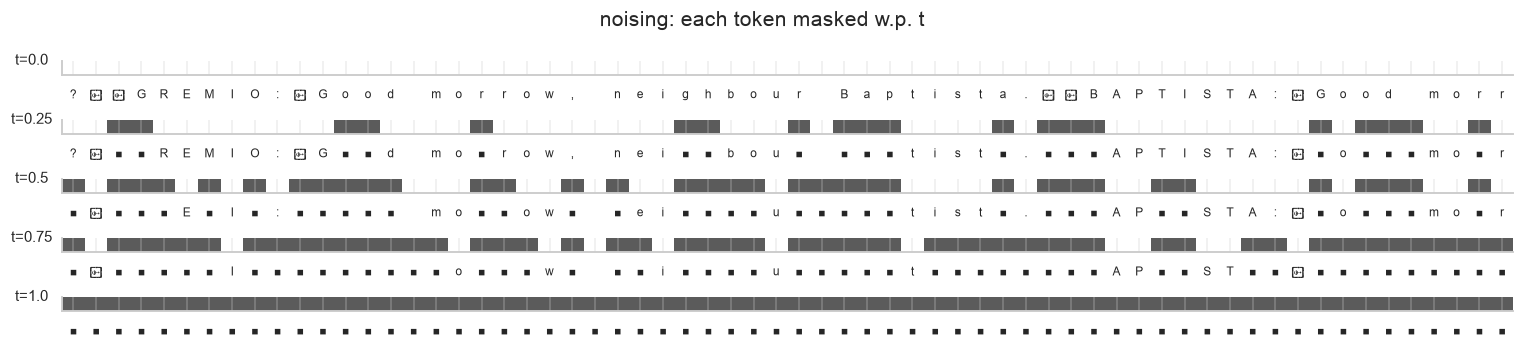

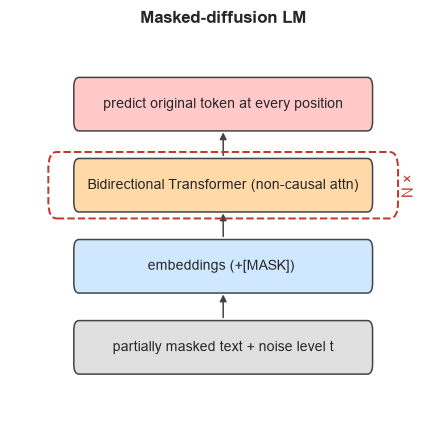

In [2]:
s = val[:64]; g = torch.Generator().manual_seed(0); u = torch.rand(64, generator=g)
fig, ax = plt.subplots(5, 1, figsize=(14, 3.2))
for a, t in zip(ax, [0.0, .25, .5, .75, 1.0]):
    m = u < t; a.imshow(m[None].float(), cmap="Greys", aspect="auto", vmin=0, vmax=1.4); a.set_yticks([]); a.set_xticks(range(64))
    a.set_xticklabels([("■" if mm else ("⏎" if data["itos"][i] == "\n" else data["itos"][i])) for i, mm in zip(s.tolist(), m)], fontsize=8); a.set_ylabel(f"t={t}", rotation=0, labelpad=20)
plt.suptitle("noising: each token masked w.p. t"); plt.tight_layout(); plt.show()
block_diagram([("predict original token at every position", "out"), ("Bidirectional Transformer (non-causal attn)", "attn*"), ("embeddings (+[MASK]) ", "embed"), ("partially masked text + noise level t", "other")][::-1], title="Masked-diffusion LM", repeat="N ×")

# ## Model: a bidirectional Transformer
# (Same blocks as BERT — the *training objective and sampler* make it generative.)

795,520 params


300 5.080


600 4.774


900 4.475


1200 4.334


1500 4.236


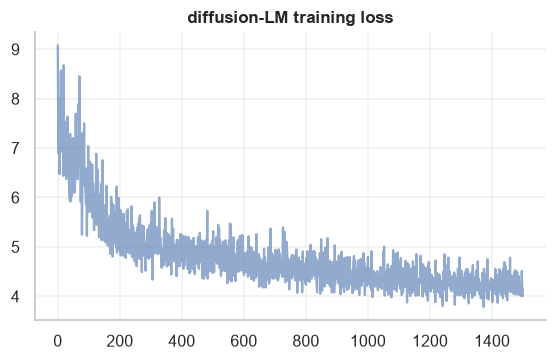

val masked-token CE: 2.502


{'name': '13 Masked diffusion LM (masked-token CE)',
 'params': 795520,
 'steps': 1500,
 'val_loss': 2.5096047683614655,
 'train_loss': 4.2065349817276,
 'note': 'masked-token CE, not next-token loss'}

In [3]:
d = 128
model = DecoderLM(V + 1, d, [Block(d, Attention(d, 4, causal=False, rope=True, bias=False), SwiGLU(d)) for _ in range(4)]).to(device)
print(f"{count_params(model):,} params")
opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=.01); sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=STEPS, pct_start=.1); ls = []
for step in range(1, STEPS + 1):
    x, _ = get_batch(train, T, 64, device); t = torch.rand(x.size(0), 1, device=device).clamp(min=.05)
    m = torch.rand(x.shape, device=device) < t; lg = model(x.masked_fill(m, MASK))[..., :V]
    loss = (F.cross_entropy(lg.transpose(1, 2), x, reduction="none") * m / t).sum() / m.sum().clamp(min=1)   # 1/t weighting
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); ls.append(loss.item())
    if step % 300 == 0: print(step, f"{np.mean(ls[-50:]):.3f}")
plt.figure(figsize=(6, 3.4)); plt.plot(ls, alpha=.6); plt.title("diffusion-LM training loss"); plt.grid(alpha=.3); plt.show()
@torch.no_grad()
def nll_bound(n=20):                            # masked-token CE at random t on validation (rough comparability)
    model.eval(); tot = []
    for _ in range(n):
        x, _ = get_batch(val, T, 64, device); t = torch.rand(x.size(0), 1, device=device).clamp(min=.05); m = torch.rand(x.shape, device=device) < t
        tot.append((F.cross_entropy(model(x.masked_fill(m, MASK))[..., :V].transpose(1, 2), x, reduction="none") * m).sum().item() / m.sum().item())
    return float(np.mean(tot))
print("val masked-token CE:", round(nll_bound(), 3))
save_result("13 Masked diffusion LM (masked-token CE)", model, {"val": [nll_bound()], "train": ls}, extra={"note": "masked-token CE, not next-token loss"})

# ## Sampling: parallel iterative unmasking
# At every step the model predicts all masked positions; we commit the most confident ones and leave the rest masked.

In [4]:
@torch.no_grad()
def sample(steps=16, seed=0):
    torch.manual_seed(seed); model.eval(); x = torch.full((1, T), MASK, device=device); frames = [x.clone()]
    for s in range(steps):
        lg = model(x)[0, :, :V]; probs = lg.softmax(-1); conf, pred = probs.max(-1)
        conf = torch.where(x[0] == MASK, conf, torch.full_like(conf, -1))           # only masked positions compete
        n_left = int((x[0] == MASK).sum()); n_unmask = int(np.ceil(n_left / (steps - s)))
        samp = torch.multinomial(probs, 1)[:, 0]; chosen = conf.topk(n_unmask).indices
        x[0, chosen] = torch.where(torch.rand(len(chosen), device=device) < .3, samp[chosen], pred[chosen])
        frames.append(x.clone())
    return frames
frames = sample(16)
show = lambda f: "".join("▒" if i == MASK else ("⏎" if data["itos"][i] == "\n" else data["itos"][i]) for i in f[0].tolist())
for k in [0, 2, 4, 8, 12, 16]: print(f"step {k:2d}: {show(frames[k])}")

step  0: ▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒
step  2: ▒▒▒▒:the ▒▒▒▒▒▒▒▒▒▒▒▒ ▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒ ▒o▒▒▒▒▒▒▒
step  4: ▒▒▒▒:the of ▒▒▒▒▒▒▒▒▒ ▒o▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒ to th▒▒▒▒
step  8: ▒▒▒e:the of so  ⏎▒o▒e come  ▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒ to the  ▒
step 12:  the:the of so  ⏎▒ose come  to ▒o   ▒▒▒▒▒▒▒▒▒▒▒▒▒n tof to the  ▒
step 16:  the:the of so  ⏎Cose come  to to   you Low the en tof to the  t


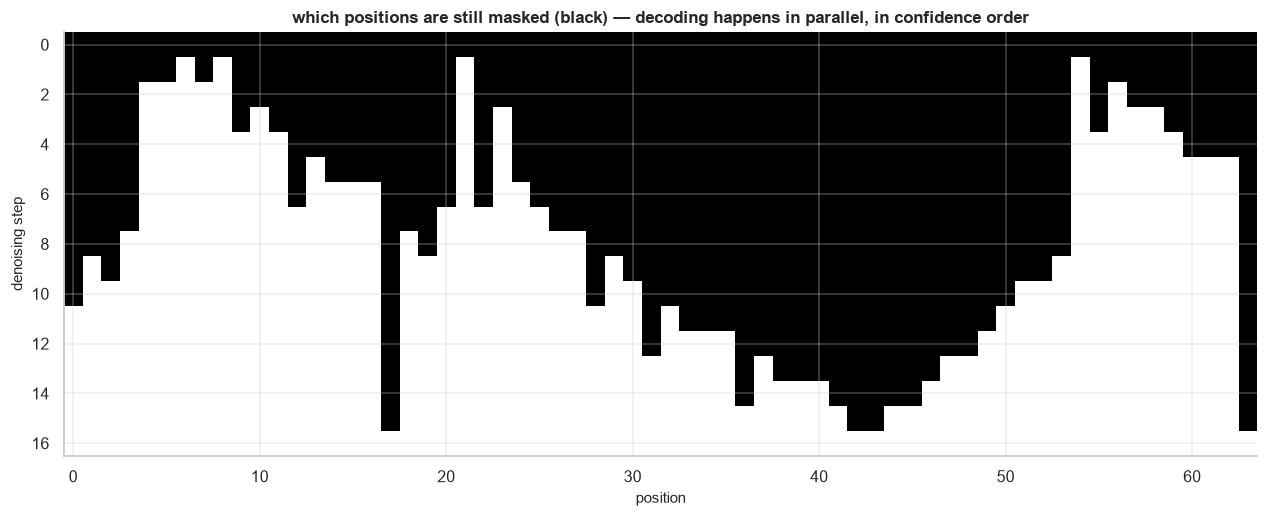

In [5]:
grid = torch.stack([f[0].cpu() for f in frames]); fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow((grid == MASK).float(), cmap="Greys", aspect="auto"); ax.set_xlabel("position"); ax.set_ylabel("denoising step")
ax.set_title("which positions are still masked (black) — decoding happens in parallel, in confidence order"); plt.show()

# ## Fewer steps = faster but rougher

In [6]:
for st in [4, 8, 32]: print(f"{st:2d} steps:", show(sample(st)[-1]))

 4 steps:  us E hf a    nou toe thee yooe lose ton   ee toae hou  the your
 8 steps:  iy I hf to to r thee gooc to so  lith oe⏎ aot too mae to cet bo
32 steps: l to ande, in bla, he ther you enty nou  to thee we te ther pou 


# ## Infilling for free (bidirectional context)
# Fix a prefix **and** a suffix, mask the middle — an autoregressive model cannot do this natively.

In [7]:
@torch.no_grad()
def infill(text_ids, lo, hi, steps=12):
    x = text_ids.clone()[None].to(device); x[0, lo:hi] = MASK
    for s in range(steps):
        lg = model(x)[0, :, :V]; conf, pred = lg.softmax(-1).max(-1); conf = torch.where(x[0] == MASK, conf, torch.full_like(conf, -1))
        k = int(np.ceil((x[0] == MASK).sum().item() / (steps - s))); sel = conf.topk(k).indices; x[0, sel] = pred[sel]
    return x
src = val[1000:1064]; out = infill(src, 20, 44)
print("original :", data["decode"](src.tolist()).replace("\n", "⏎")); print("infilled :", data["decode"](out[0].tolist()).replace("\n", "⏎")); print("masked   :", " " * 20 + "^" * 24)

original : rina, this I know,⏎She is not for your turn, the more my grief.⏎
infilled : rina, this I know,⏎Sooe yow  to lome in thee the more my grief.⏎
masked   :                     ^^^^^^^^^^^^^^^^^^^^^^^^


---

## Key takeaways

- Generation order is free: positions are decoded in confidence order, not left-to-right.
- Quality/speed trade-off is controlled by the number of denoising steps.
- Bidirectional context gives native infilling.

## References

- [Nie et al., *Large Language Diffusion Models* (LLaDA, 2025)](https://arxiv.org/abs/2502.09992)
- [Sahoo et al., *Simple and Effective Masked Diffusion Language Models* (2024)](https://arxiv.org/abs/2406.07524)

---
*← previous: `12_vision_transformer_and_vlm`  ·  next: `99_comparison` →*